# Choosing the lexical K by marginal yield

`03_lexical_retrieval.ipynb` returns a fixed top 1,000 (proposal Section 4.2). This notebook tests that depth with the **marginal-yield method used on the `semantic-search` branch** (`marginal_yield.py`, `method_and_findings.txt`), so both channels choose their depth the same way.

**Marginal yield** = new distinct credible investigative leads ÷ emails assessed in that rank band.

| Step | What | Same as the semantic pilot? |
|---|---|---|
| Ranking | The saved full ranking of run `LEXICAL_RUN` (`lexical_rule_audit.parquet`, every eligible email) | Yes: fixed before sampling, ties by `email_id` |
| Bands | 1-100, 101-200, 201-300, 301-500, **501-1000, 1001-1500** | First four identical; two added because the current K is 1,000 and stopping there needs a band beyond it |
| Sample | 40 emails per band without replacement, seed 6450 | Yes |
| Verdicts | `credible_lead`, `context`, `unclear`, `irrelevant`; a lead needs a registered case ID | Yes, same rubric (section 4) |
| Case counting | One shared lead registry; a case counts once, at the first band that finds it; cases known before the pilot never count | Yes: the registry starts from the semantic pilot's |
| Stopping rule | Two consecutive completely-assessed bands with yield below 1%; the first band does not count | Yes |
| Added | On-topic rate (`credible_lead` + `context`) per band, SPE-subset recall and seed ranks by depth | New: lexical hits cluster on known deals, so new-case yield alone falls fast |

Judgements are stored in `data/lexical_marginal_yield/assessments.json` (committed with the code), separate from the ranking. `review_plan.json` there fingerprints the ranking and the sample, so a changed plan cannot silently re-use saved judgements.

## 1. Configuration

In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 220)

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUT_ROOT = Path('E:/University-Georgia Tech/INTA6450_dataanalytics_security/project')
LEXICAL_RUN = '20261123T011207Z'                    # final option 3 run of 03_lexical_retrieval.ipynb
RUN_DIR = OUTPUT_ROOT / 'lexical_outputs' / LEXICAL_RUN
OUT = RUN_DIR / 'marginal_yield'                    # sheets, tables and chart for this pilot
REVIEW_DIR = REPO_ROOT / 'data' / 'lexical_marginal_yield'   # committed: plan fingerprint, judgements, lead registry
SPE_SUBSET_PATH = REPO_ROOT / 'data' / 'spe_subset_emails.csv'

DEPTHS = (100, 200, 300, 500, 1000, 1500)   # band upper ranks; the semantic pilot used the first four
SAMPLE_SIZE = 40
SEED = 6450                                 # same seed as the semantic pilot
LOW_YIELD = 0.01                            # stopping rule: two consecutive complete bands below this
CURRENT_K = 1000

config = json.loads((RUN_DIR / 'lexical_config.json').read_text(encoding='utf-8'))
SEED_EMAILS = {'c9732ecec3d1333cbf8ce9d461b7fe7f': 'Kaminski, "LJM/Raptor valuations"',
               'f6a682d86455b20afb09bfde1adf2b76': 'Pruett, "CGAS Hawaii Sec 125 Trust"'}
OUT.mkdir(exist_ok=True)
REVIEW_DIR.mkdir(exist_ok=True)
print(f"Lexical run {LEXICAL_RUN}: query option {config['query_option']} ({config['query']}), "
      f"{config['counts']['eligible']:,} eligible emails, cleaning run {config['cleaning_run']}")

Lexical run 20261123T011207Z: query option 3 (Table 2 terms only), 122,796 eligible emails, cleaning run 20261121T041323916929Z


## 2. The full ranking and what deeper K adds without labels

Pool size, rule matches, SPE-subset recall and seed ranks at each depth. The SPE subset was found with the same names as the dictionary, so its recall shows coverage, not accuracy; it supports the choice of K but cannot decide it.

In [2]:
AUDIT_PATH = RUN_DIR / 'lexical_rule_audit.parquet'
ranking = pd.read_parquet(AUDIT_PATH).sort_values('lex_rank').reset_index(drop=True)
assert len(ranking) == config['counts']['eligible'] and ranking['email_id'].is_unique
assert (ranking['lex_rank'].to_numpy() == np.arange(1, len(ranking) + 1)).all()
top1000 = pd.read_csv(RUN_DIR / 'lexical_top1000.csv', usecols=['lex_rank', 'email_id'])
assert top1000['email_id'].tolist() == ranking['email_id'].head(CURRENT_K).tolist(), 'audit ranking must match the saved top 1000'

rank_of = ranking.set_index('email_id')['lex_rank']
spe = pd.read_csv(SPE_SUBSET_PATH, usecols=['email_id', 'prime'])
spe = spe[spe['email_id'].isin(rank_of.index)].assign(lex_rank=lambda d: d['email_id'].map(rank_of))

depth_rows, lower = [], 0
for upper in DEPTHS:
    band = ranking.iloc[lower:upper]
    depth_rows.append({'k': upper, 'band': f'{lower + 1}-{upper}', 'rule_matches_in_band': int(band['rule_match'].sum()),
                       'tfidf_score_at_k': round(float(ranking['tfidf_score'].iloc[upper - 1]), 4),
                       'spe_recall_at_k': f"{(spe['lex_rank'] <= upper).sum()}/{len(spe)}",
                       'prime_spe_recall_at_k': f"{(spe.loc[spe['prime'], 'lex_rank'] <= upper).sum()}/{int(spe['prime'].sum())}",
                       'seeds_within_k': sum(rank_of[s] <= upper for s in SEED_EMAILS)})
    lower = upper
depth_table = pd.DataFrame(depth_rows)
depth_table.to_csv(OUT / 'depth_profile.csv', index=False)
display(depth_table)
print('Seed ranks:', {SEED_EMAILS[s]: int(rank_of[s]) for s in SEED_EMAILS})

,k,band,rule_matches_in_band,tfidf_score_at_k,spe_recall_at_k,prime_spe_recall_at_k,seeds_within_k
0,100,1-100,100,0.0250,87/423,74/231,2
1,200,101-200,14,0.0573,131/423,97/231,2
2,300,201-300,0,0.0471,154/423,109/231,2
3,500,301-500,0,0.0388,189/423,133/231,2
4,1000,501-1000,0,0.0317,225/423,159/231,2
5,1500,1001-1500,0,0.0283,241/423,171/231,2


Seed ranks: {'Kaminski, "LJM/Raptor valuations"': 14, 'Pruett, "CGAS Hawaii Sec 125 Trust"': 5}


## 3. Fixed sample

40 emails per band, drawn exactly as `marginal_yield.py prepare` draws them (one generator, seed 6450, bands in order). Writes the review sheet and stores the plan fingerprint; if a saved plan differs, the notebook stops rather than re-use judgements made on another sample.

In [3]:
rng = np.random.default_rng(SEED)
jobs, lower = [], 0
for upper in DEPTHS:
    band = ranking.iloc[lower:upper]
    for i in np.sort(rng.choice(len(band), size=min(SAMPLE_SIZE, len(band)), replace=False)):
        row = band.iloc[int(i)]
        jobs.append({'lower_k': lower, 'upper_k': upper, 'email_id': row['email_id'], 'lex_rank': int(row['lex_rank']),
                     'rule_type': row['rule_type'], 'tfidf_score': float(row['tfidf_score']), 'band_population': len(band)})
    lower = upper
jobs = pd.DataFrame(jobs)
jobs.insert(0, 'review_id', [f'L{i:03d}' for i in range(1, len(jobs) + 1)])
assert jobs['email_id'].is_unique   # bands are disjoint and there is one ranking, so no email repeats

plan = {'lexical_run': LEXICAL_RUN, 'depths': list(DEPTHS), 'sample_size': SAMPLE_SIZE, 'seed': SEED,
        'ranking_sha256': hashlib.sha256(ranking[['lex_rank', 'email_id']].to_csv(index=False).encode()).hexdigest(),
        'jobs_sha256': hashlib.sha256(jobs[['review_id', 'email_id', 'lex_rank']].to_csv(index=False).encode()).hexdigest()}
plan_path = REVIEW_DIR / 'review_plan.json'
if plan_path.exists() and json.loads(plan_path.read_text(encoding='utf-8')) != plan:
    raise ValueError('Saved review plan differs: preserve assessments.json before making a new plan')
plan_path.write_text(json.dumps(plan, indent=2), encoding='utf-8')
jobs.to_csv(OUT / 'review_jobs.csv', index=False)

# Review text: what TF-IDF scored (subject + new text) and the full cleaned email for context
emails = pq.read_table(OUTPUT_ROOT / 'enron_cleaning_outputs' / config['cleaning_run'] / 'emails_analysis.parquet',
                       columns=['email_id', 'date_utc', 'sender', 'recipients', 'cc', 'subject', 'body_retrieval', 'body_clean'],
                       filters=[('email_id', 'in', jobs['email_id'].tolist())]).to_pandas()
people = lambda v, n=6: ', '.join(list(v)[:n]) + (f' (+{len(v) - n} more)' if len(v) > n else '')
emails = emails.assign(date_houston=emails['date_utc'].dt.tz_convert('America/Chicago').dt.strftime('%Y-%m-%d %H:%M'),
                       sender=emails['sender'].map(people), recipients=emails['recipients'].map(people), cc=emails['cc'].map(people))
review = jobs.merge(emails.drop(columns='date_utc'), on='email_id', validate='one_to_one').merge(
    ranking[['email_id', 'names', 'groups']], on='email_id', validate='one_to_one')
review.to_parquet(OUT / 'review_emails.parquet', index=False)

from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE   # control characters Excel cannot store
clip = lambda t, n=4000: ILLEGAL_CHARACTERS_RE.sub('', t if len(t) <= n else t[:n] + f'\n[... {len(t) - n:,} more characters]')
sheet = review.assign(body_retrieval=review['body_retrieval'].map(clip), body_clean=review['body_clean'].map(clip),
                      subject=review['subject'].map(lambda t: ILLEGAL_CHARACTERS_RE.sub('', t)),
                      verdict='', lead_id='', rationale='')
sheet[['review_id', 'email_id', 'lower_k', 'upper_k', 'lex_rank', 'rule_type', 'names', 'date_houston', 'sender', 'recipients',
       'subject', 'body_retrieval', 'body_clean', 'verdict', 'lead_id', 'rationale']].to_excel(OUT / 'review_sheet.xlsx', index=False)
print(f'{len(jobs)} sampled emails ({SAMPLE_SIZE} per band), plan saved to {plan_path.relative_to(REPO_ROOT)}')
print(jobs.groupby('upper_k').agg(sampled=('email_id', 'size'), band_population=('band_population', 'first'),
                                  rule_matches=('rule_type', lambda s: int((s != '').sum()))).to_string())

240 sampled emails (40 per band), plan saved to data\lexical_marginal_yield\review_plan.json
         sampled  band_population  rule_matches
upper_k                                        
100           40              100            40
200           40              100             4
300           40              100             0
500           40              200             0
1000          40              500             0
1500          40              500             0


## 4. Assessment rubric

Copied from the semantic pilot so the two channels' yields mean the same thing.

| Verdict | Meaning |
|---|---|
| `credible_lead` | A **named transaction or product with a concrete retained-risk, protection-capacity or representation issue worth tracing**. Not a finding of wrongdoing, and it need not yet show all three evidence conditions (risk, knowledge, contradictory action). Needs a `lead_id` in `lead_registry.json`. |
| `context` | Substantive about an SPE, related-party deal, monetization, hedge of Enron's own assets or a structured-finance arrangement, but no concrete issue to trace. |
| `unclear` | Cannot tell from the text (bare attachment notes, fragments). Not an established negative. |
| `irrelevant` | Routine trading, credit or legal paperwork, policy notices, news digests, scheduling, social; or a deal named only in passing. |

Routine drafting, policy notices, second-hand news, bare entity names and lawful mitigation do not qualify as leads by themselves.

**Case counting.** A lead counts once, at the first band that finds it; later emails on the same case support it but add nothing. Cases marked `known_before_pilot` never count: Mahonia, as in the semantic pilot. The cases the semantic pilot found are not known before *this* channel's curve, just as the semantic pilot counted each pattern's curve separately; the `also_semantic` column shows which leads both channels found. The seed cases are not marked known either, as in the semantic pilot; both seeds rank in 1-100, which does not count toward the stopping rule, so this choice cannot change K.

In [4]:
registry = json.loads((REVIEW_DIR / 'lead_registry.json').read_text(encoding='utf-8'))
assessment_file = REVIEW_DIR / 'assessments.json'
saved = json.loads(assessment_file.read_text(encoding='utf-8')) if assessment_file.exists() else {'assessments': {}}
assessments = saved['assessments']
VERDICTS = {'credible_lead', 'context', 'unclear', 'irrelevant'}
unknown = set(assessments) - set(jobs['email_id'])
assert not unknown, f'judgements for emails outside the sample: {sorted(unknown)[:3]}'
for email_id, item in assessments.items():
    assert item['verdict'] in VERDICTS and item.get('rationale'), f'{email_id}: invalid verdict or missing rationale'
    lead = item.get('lead_id', '')
    assert lead == '' or lead in registry, f'{email_id}: unknown lead {lead}'
    assert item['verdict'] != 'credible_lead' or lead, f'{email_id}: a credible lead needs a registered case ID'

reviewed = jobs.assign(verdict=jobs['email_id'].map(lambda e: assessments.get(e, {}).get('verdict', 'unreviewed')),
                       lead_id=jobs['email_id'].map(lambda e: assessments.get(e, {}).get('lead_id', '')),
                       rationale=jobs['email_id'].map(lambda e: assessments.get(e, {}).get('rationale', '')))
reviewed.merge(review[['email_id', 'subject', 'date_houston', 'sender']], on='email_id').to_csv(
    OUT / 'reviewed_jobs.csv', index=False, encoding='utf-8-sig')

known = {k for k, v in registry.items() if v.get('known_before_pilot')}
semantic_cases = {k for k, v in registry.items() if v.get('source') == 'semantic pilot'}
seen, streak, rows = set(known), 0, []
for k in DEPTHS:
    band = reviewed[reviewed['upper_k'] == k]
    done = band[band['verdict'] != 'unreviewed']
    complete = len(done) == len(band)
    accepted = set(done.loc[done['verdict'] == 'credible_lead', 'lead_id'])
    new = accepted - seen
    seen |= accepted
    rate = len(new) / len(done) if len(done) else None
    if k == DEPTHS[0]:
        streak = 0                      # the first band does not count toward two low increments
    elif complete and rate < LOW_YIELD:
        streak += 1
    else:
        streak = 0
    rows.append({'k': k, 'band': f"{int(band['lower_k'].iloc[0]) + 1}-{k}", 'assessed': len(done), 'complete': complete,
                 'credible_lead_emails': int((done['verdict'] == 'credible_lead').sum()),
                 'new_distinct_leads': len(new), 'new_lead_ids': ', '.join(sorted(new)),
                 'also_semantic': ', '.join(sorted(new & semantic_cases)),
                 'marginal_yield': rate, 'on_topic_rate': ((done['verdict'].isin(['credible_lead', 'context'])).mean() if len(done) else None),
                 'unclear': int((done['verdict'] == 'unclear').sum()), 'two_low_increments': streak >= 2})
yield_table = pd.DataFrame(rows)
yield_table.to_csv(OUT / 'marginal_yield.csv', index=False)
print(f"{len(assessments)}/{len(jobs)} sampled emails assessed. Reviewer: {saved.get('reviewer', 'none yet')}")
display(yield_table.assign(marginal_yield=yield_table['marginal_yield'].map(lambda r: '' if r is None else f'{r:.1%}'),
                           on_topic_rate=yield_table['on_topic_rate'].map(lambda r: '' if r is None else f'{r:.0%}')))
display(reviewed.groupby('upper_k')['verdict'].value_counts().unstack(fill_value=0))

240/240 sampled emails assessed. Reviewer: Claude (AI first pass); not yet checked by a person


,k,band,assessed,complete,credible_lead_emails,new_distinct_leads,new_lead_ids,also_semantic,marginal_yield,on_topic_rate,unclear,two_low_increments
0,100,1-100,40,True,5,3,"HAWAII_125_0_TRS_RETAINED_RISK, LJM1_PUT_CREDIT_RESERVE, RAPTOR_CAPACITY_AND_ASSURANCES",RAPTOR_CAPACITY_AND_ASSURANCES,7.5%,82%,1,False
1,200,101-200,40,True,2,2,"CHEWCO_JEDI_OWNERSHIP, LV_COGEN_FRIEND_OF_ENRON_CONTROL",,5.0%,40%,11,False
2,300,201-300,40,True,2,0,,,0.0%,45%,5,False
3,500,301-500,40,True,0,0,,,0.0%,38%,2,True
4,1000,501-1000,40,True,1,1,LGI_FIDELITY_GUARANTY,,2.5%,12%,2,False
5,1500,1001-1500,40,True,0,0,,,0.0%,0%,0,False


verdict,context,credible_lead,irrelevant,unclear
upper_k,,,,
100,28,5,6,1
200,14,2,13,11
300,16,2,17,5
500,15,0,23,2
1000,4,1,33,2
1500,0,0,40,0


In [5]:
# The K the rule supports: the first depth where two consecutive low bands are observed, provided no later
# sampled band (the look-ahead) finds a new lead. If a later band does, the rule's K is not safe.
low = yield_table[yield_table['two_low_increments']]
later_finds = lambda k: yield_table[(yield_table['k'] > k) & (yield_table['new_distinct_leads'] > 0)]
if not yield_table['complete'].all():
    verdict = 'Assessment incomplete: no K decision yet.'
elif low.empty:
    verdict = f'No two consecutive low bands through {DEPTHS[-1]}: the sample does not support a stopping depth.'
else:
    rule_k = int(low['k'].iloc[0])
    after = later_finds(rule_k)
    verdict = (f'Stopping rule first met at K={rule_k}; no later band through {DEPTHS[-1]} found a new lead.' if after.empty else
               f"Stopping rule first met at K={rule_k}, but band(s) {', '.join(after['band'])} found new leads, so K={rule_k} is not safe.")
print(verdict)

Stopping rule first met at K=500, but band(s) 501-1000 found new leads, so K=500 is not safe.


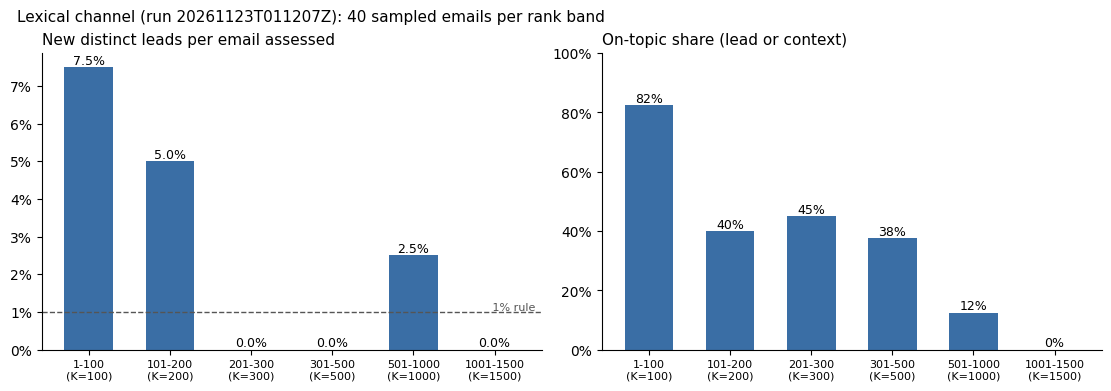

In [6]:
import matplotlib.pyplot as plt

t = yield_table.dropna(subset=['marginal_yield'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
x = np.arange(len(t))
labels = [f"{b}\n(K={k})" for b, k in zip(t['band'], t['k'])]
for ax, column, title, fmt in [(axes[0], 'marginal_yield', 'New distinct leads per email assessed', '{:.1%}'),
                               (axes[1], 'on_topic_rate', 'On-topic share (lead or context)', '{:.0%}')]:
    ax.bar(x, t[column], width=0.6, color='#3a6ea5')
    for xi, v in zip(x, t[column]):
        ax.text(xi, v, fmt.format(v), ha='center', va='bottom', fontsize=9)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set_title(title, fontsize=11, loc='left')
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axes[0].axhline(LOW_YIELD, color='#555555', ls='--', lw=1)
axes[0].text(len(t) - 0.5, LOW_YIELD, ' 1% rule', va='bottom', ha='right', fontsize=8, color='#555555')
axes[1].set_ylim(0, 1)
fig.suptitle(f'Lexical channel (run {LEXICAL_RUN}): 40 sampled emails per rank band', fontsize=11, x=0.01, ha='left')
fig.savefig(OUT / 'marginal_yield_vs_k.png', dpi=150)
plt.show()

## 5. K decision: keep K = 1,000

**Result (240 emails, AI first pass, not yet checked by a person).**

| Band | New distinct leads | Yield | On-topic | New cases |
|---|---|---|---|---|
| 1-100 | 3 | 7.5% | 82% | Hawaii 125-0 TRS retained risk; LJM1 put credit reserve; Raptor capacity (also found by the semantic pilot) |
| 101-200 | 2 | 5.0% | 40% | Chewco owned in part by Enron (96.12% of JEDI I); Las Vegas Cogen "Friend of Enron" control |
| 201-300 | 0 | 0% | 45% | (two more Raptor-capacity emails, case already counted) |
| 301-500 | 0 | 0% | 38% | |
| 501-1000 | **1** | **2.5%** | 12% | **Landfill Gas Investments: Enron guaranty behind Fidelity's 99% interest (rank 645)** |
| 1001-1500 | 0 | 0% | 0% | |

**Decision.** The stopping rule (two complete bands below 1%) is first met at **K = 500**, but the look-ahead band 501-1000 finds a new case, so K = 500 is **not safe**. This is the same thing the semantic pilot saw for HOW MUCH (two empty bands, then two leads in 301-500). Below 1,000 the evidence points to stopping: 1001-1500 has no lead and **no on-topic email** (40 of 40 irrelevant: digests, ISDA paperwork, trading admin), and it adds only 16 of the 423 SPE-subset emails (225 to 241). **Keep K = 1,000**, the proposal's value.

**Limits.**
- One case moves a band's yield by 2.5 points, and a zero cannot show the population yield is below 1%. Do not multiply sampled yield by band size.
- The strict rule needs a second low band after 1,000. A 1501-2000 band (40 more emails, same seed continuing) would close that; the on-topic rate already at 0% makes a lead there unlikely.
- Case grouping is a judgement: Raptor is one umbrella case, as in the semantic pilot. Splitting it would raise the 1-300 yields but not change the decision, which rests on 501-1000 and 1001-1500.
- The judgements are an AI first pass from the scored text, with the full text read for the 7 candidate leads. A person should check at least the 10 `credible_lead` rows and the 21 `unclear` rows before this is reported as final.

**For fusion.** Five of the six lexical cases were not found in the semantic pilot's sample (Hawaii 125-0, LJM1, Chewco/JEDI, Las Vegas Cogen, Landfill Gas), and the semantic pilot's UtiliQuest and steel cases were not in this sample. The channels find different cases, which supports fusing them.